## Simple blog Writer using Prompt Chaining and LangGraph

In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from typing import TypedDict
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
model = ChatOpenAI()

In [4]:
prompt = "what is the capital of france? answer in one word only"
result = model.invoke(prompt)

In [5]:
result.content

'Paris'

In [6]:
result


AIMessage(content='Paris', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 1, 'prompt_tokens': 19, 'total_tokens': 20, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'id': 'chatcmpl-DfRuLl6I3MdaF1CaPK93GHlqM5ZVH', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019e2704-f6c6-7bf1-a416-13ca4ae3ba4f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 19, 'output_tokens': 1, 'total_tokens': 20, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [7]:
model.model_name

'gpt-3.5-turbo'

## Prompt Chaining

In [8]:
class BlogState(TypedDict):
    title: str
    outline: str
    content: str
    formatted_html_blog: str

In [9]:
## node defining to use
def create_outline(state:BlogState)-> BlogState:
    ## fetching title from state
    title = state['title']

    ## creating prompt for outline generation
    prompt = f"Create a detailed outline for a blog post with the title: '{title}'"

    outline = model.invoke(prompt).content

    return {'outline': outline}

In [10]:
def create_blog(state:BlogState)-> BlogState:
    title = state['title']
    outline = state['outline']

    prompt = f"""You are blog writer specialist, you look at raw outline of blog for given topic and write best block out of it.Write a blog post based on the following title outline
    Title: {title}
    Outline:{outline}"""

    content = model.invoke(prompt).content

    return {'content': content}


In [11]:
def format_html_blog(state:BlogState) -> BlogState:
    content = state['content']

    prompt = f"""You are a blog formatter, you look at raw  content of blog and format it in html format. Here is the  content:\n\n{content}"""

    formatted_html_blog = model.invoke(prompt).content

    return {'formatted_html_blog': formatted_html_blog}

In [12]:
graph  = StateGraph(BlogState)


#nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)
graph.add_node('format_html_blog', format_html_blog)

## edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', 'format_html_blog')
graph.add_edge('format_html_blog',END)

## workflow compilation
workflow = graph.compile()

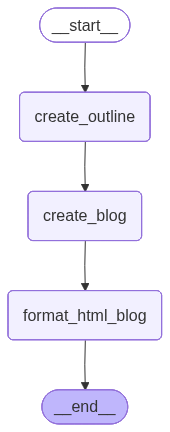

In [13]:
workflow

In [14]:
intial_state = {
    'title': "Robotics PAST, PRESENT, AND FUTURE"
}

In [15]:
final_state = workflow.invoke(intial_state)

In [16]:
html = final_state['formatted_html_blog']

In [17]:
from IPython.display import display, HTML
display(HTML(html))